# STATS 425 · Week 10 lab
**From probabilities to trustworthy answers**  
**TA:** Ali Kaazempur-Mofrad

Over the past nine weeks, we measured a model's probabilities (Weeks 1 and 3), changed its weights with desired responses (Week 2), with rewards (Weeks 4–6), and with preferences (Week 7), asked whether its confidence can be trusted (Weeks 6 and 8), and retrieved evidence before answering (Week 9). Today, we review the course by following **one task from start to finish**, reusing each week's idea in a few lines of code.

**The task.** We use Week 6's noisy version of "Which number is largest?". The model sees each number with random noise added, so even a good policy is sometimes wrong. Its response has two parts, generated one after the other: an answer letter, then a confidence level.

**How this maps to a language model.** A model might write `B`, then `Confidence: 0.7`; a verifier checks the answer, and the reward scores both parts.

| Section | Question we answer |
|---|---|
| 1. Probabilities and loss | What does the starting policy predict, and how do we score it? |
| 2. A supervised start | How do labeled examples give us a reasonable reference policy? |
| 3. Rewards for answers and confidence | Can rewards make the stated confidence trustworthy while staying close to the reference? |
| 4. Answering with a guarantee | How do we turn the trained policy into answers with error control? |
| 5. A one-page map | Where did each week's idea appear today? |

**Set up the notebook.** The cell below imports the libraries and sets a random seed so the results are repeatable; exact numbers may differ slightly across PyTorch versions.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("torch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch>=2.8,<3"])

import copy
import itertools
import math
import random

import matplotlib.pyplot as plt
import torch
from torch import nn  # PyTorch's neural-network module
from torch.distributions import Categorical

SEED = 425
torch.manual_seed(SEED)
torch.set_num_threads(1)

COLORS = ("#2874A6", "#C0392B", "#7F8C8D")

print(f"Setup complete. PyTorch {torch.__version__}")

Setup complete. PyTorch 2.8.0+cu128


## 1 · Probabilities and loss

**The prompt.** As in Weeks 4 and 6, the task uses three different integers from 1 through 9, labeled A, B, and C: the **true numbers** $x=(x_A,x_B,x_C)$. As in Week 6, the model does not see them exactly. It sees each one with independent Gaussian noise added:

$$
\tilde x_j = x_j+\sigma\varepsilon_j,
\qquad \varepsilon_j\sim\mathcal N(0,1)\ \text{independently},
\qquad j\in\{A,B,C\},
\qquad \sigma=1.5 .
$$

The verifier knows the true numbers and judges the answer on them. When two observed values are close, the noise may have swapped their order, so even a very good policy cannot always be right.

**The response.** As in Week 6, a response $y=(a,q)$ has two parts, generated one after the other:

1. an **answer** $a\in\{A,B,C\}$;
2. a **confidence level** $q\in\{0.1, 0.3, 0.5, 0.7, 0.9\}$: the model's reported probability that its answer is correct.

The verifier returns the correctness $c=\mathbf{1}\{\text{the chosen answer holds the largest true number}\}$. We write $a^*$ for the correct answer.

**Build the data.** We reuse Week 4's split of the 84 groups of three numbers: 64 groups (in all six orders) for training and 20 held-out groups. A training prompt receives fresh noise every time we draw it. From the held-out groups, we draw a **calibration set** of 1000 observed prompts and a **test set** of 2000 observed prompts, each with its own noise. Section 4 explains why we keep these two sets separate.

The code prints one example prompt, its hidden true numbers, and the verifier's output for each possible answer.

In [2]:
LETTERS = ("A", "B", "C")
LEVELS = torch.tensor([0.1, 0.3, 0.5, 0.7, 0.9])  # allowed confidence levels q
SIGMA = 1.5  # standard deviation of the observation noise


def format_prompt(observed):
    options = "    ".join(f"{letter}: {float(value):.1f}" for letter, value in zip(LETTERS, observed))
    return (f"Which number is largest?\n{options}\n"
            "Respond with A, B, or C, then your confidence that the answer is correct.")


def verify(true_numbers, answer):
    return float(true_numbers[answer] == max(true_numbers))


def expand_orders(groups):
    return torch.tensor([
        ordering
        for group in groups
        for ordering in itertools.permutations(group)
    ], dtype=torch.float32)


def draw_prompts(true_pool, n, generator=None):
    rows = torch.randint(len(true_pool), (n,), generator=generator)
    true_numbers = true_pool[rows]
    observed = true_numbers + SIGMA * torch.randn(true_numbers.shape, generator=generator)
    return true_numbers, observed


groups = list(itertools.combinations(range(1, 10), 3))
random.Random(SEED).shuffle(groups)
train_groups, heldout_groups = groups[:64], groups[64:]
train_true = expand_orders(train_groups)
heldout_true = expand_orders(heldout_groups)

data_generator = torch.Generator().manual_seed(SEED)
cal_true, cal_obs = draw_prompts(heldout_true, 1000, data_generator)
test_true, test_obs = draw_prompts(heldout_true, 2000, data_generator)
cal_answers = cal_true.argmax(dim=1)    # index of the largest TRUE number
test_answers = test_true.argmax(dim=1)

EXAMPLE_TRUE = (2, 7, 6)
EXAMPLE_OBS = torch.tensor([2.6, 6.1, 6.5])

print(f"Training pool: {len(train_groups)} groups x 6 orders = {len(train_true)} true prompts (fresh noise per draw)")
print(f"Calibration set: {len(cal_obs)} observed prompts | Test set: {len(test_obs)} observed prompts "
      f"(from {len(heldout_groups)} held-out groups)")
print("-" * 72)
print("EXAMPLE PROMPT (the model sees only the observed numbers)")
print(format_prompt(EXAMPLE_OBS))
print("-" * 72)
print(f"{'Answer':<10}{'Observed value':>16}{'True number':>14}{'Correct (c)':>14}")
for answer, letter in enumerate(LETTERS):
    print(f"{letter:<10}{EXAMPLE_OBS[answer].item():>16.1f}{EXAMPLE_TRUE[answer]:>14}"
          f"{verify(EXAMPLE_TRUE, answer):>14.0f}")

Training pool: 64 groups x 6 orders = 384 true prompts (fresh noise per draw)
Calibration set: 1000 observed prompts | Test set: 2000 observed prompts (from 20 held-out groups)
------------------------------------------------------------------------
EXAMPLE PROMPT (the model sees only the observed numbers)
Which number is largest?
A: 2.6    B: 6.1    C: 6.5
Respond with A, B, or C, then your confidence that the answer is correct.
------------------------------------------------------------------------
Answer      Observed value   True number   Correct (c)
A                      2.6             2             0
B                      6.1             7             1
C                      6.5             6             0


In the example, `C` has the largest observed value (6.5), but `B` has the largest true number (7), so only `B` earns $c=1$. A policy that always picks the largest observed value would be wrong on this prompt. The right confidence depends on the prompt: here, $\tilde x_B$ and $\tilde x_C$ are close, so a careful model should report low confidence.

**The policy.** We use Week 6's two-part policy $\pi_\theta$.

- **Answer head.** Exactly as in Week 4, applied to the observed numbers: $u=\tilde x/10$, logits $z=Wu$ with a $3\times3$ weight matrix $W$, then softmax gives $\pi_\theta(a\mid\tilde x)$.
- **Confidence head.** After choosing $a$, the policy computes the **gap of the chosen answer**, $d=\tilde x_a-\max_{j\ne a}\tilde x_j$: the chosen observed value minus the largest of the other two. It is negative when the chosen answer is not the largest observed number. As in Week 6, the confidence head is a **confidence table** of logits with one row for each gap range (`below 0`, `0 to 0.5`, `0.5 to 1`, `1 to 1.5`, `1.5 to 2`, `2 to 3`, `3 or more`) and one column for each confidence level. The row for $d$ goes through softmax to give $\pi_\theta(q\mid\tilde x,a)$. The table has $7\times5=35$ weights.

The weights $\theta$ are $W$ together with the confidence table. As in Weeks 5 and 6, the log-probability of the whole response is a sum:

$$
\ln\pi_\theta(y\mid\tilde x)=\ln\pi_\theta(a\mid\tilde x)+\ln\pi_\theta(q\mid\tilde x,a).
$$

**Score the starting policy.** All weights start at zero, so all logits are zero. As in Week 1, we score the probability of the correct answer with the log loss $-\ln\pi_\theta(a^*\mid\tilde x)$, average it over the test set, and take the exponential to get perplexity. As in Week 3, temperature $T$ divides the logits before softmax: $\pi_{\theta,T}(a\mid\tilde x)\propto\exp(z_a/T)$.

**Predict before running:** what are the starting log loss and perplexity? What do $T=0.5$ and $T=2$ do to the example's probabilities?

In [3]:
GAP_EDGES = torch.tensor([0.0, 0.5, 1.0, 1.5, 2.0, 3.0])
GAP_LABELS = ("below 0", "0 to 0.5", "0.5 to 1", "1 to 1.5", "1.5 to 2", "2 to 3", "3 or more")


def gap_bin(gap):
    # 0 for a negative gap, 1 for [0, 0.5), 2 for [0.5, 1), ..., 6 for 3 or more
    return torch.bucketize(gap, GAP_EDGES, right=True)


def chosen_gap(observed, answers):
    # d = observed value of the chosen answer minus the largest other observed value
    chosen = observed.gather(1, answers[:, None]).squeeze(1)
    others = observed.masked_fill(nn.functional.one_hot(answers, 3).bool(), float("-inf"))
    return chosen - others.max(dim=1).values


def observed_gap(observed):
    # largest observed value minus the second largest (a measure of difficulty)
    top_two = observed.topk(2, dim=1).values
    return top_two[:, 0] - top_two[:, 1]


class CalibratedPolicy(nn.Module):
    def __init__(self):
        super().__init__()
        self.answer_head = nn.Linear(3, 3, bias=False)  # Week 4's 3x3 weights W
        nn.init.zeros_(self.answer_head.weight)
        # One row of logits per gap range, one column per confidence level (as in Week 6).
        self.confidence_table = nn.Parameter(torch.zeros(len(GAP_LABELS), len(LEVELS)))

    def answer_distribution(self, observed, temperature=1.0):
        logits = self.answer_head(observed / 10.0)
        return Categorical(logits=logits / temperature)

    def confidence_distribution(self, observed, answers):
        return Categorical(logits=self.confidence_table[gap_bin(chosen_gap(observed, answers))])


@torch.no_grad()
def answer_metrics(model, observed, answers, temperature=1.0):
    probabilities = model.answer_distribution(observed, temperature).probs
    p_correct = probabilities.gather(1, answers[:, None]).squeeze(1)
    log_loss = -p_correct.log().mean().item()
    return {
        "log_loss": log_loss,
        "perplexity": math.exp(log_loss),
        "greedy_accuracy": (probabilities.argmax(dim=1) == answers).float().mean().item(),
        "sampled_accuracy": p_correct.mean().item(),
    }


torch.manual_seed(SEED)
initial_policy = CalibratedPolicy()
example = EXAMPLE_OBS[None, :]

print("STARTING ANSWER PROBABILITIES FOR THE EXAMPLE")
print(f"{'Temperature':<14}" + "".join(f"{f'P({letter})':>10}" for letter in LETTERS))
with torch.no_grad():
    for temperature in (0.5, 1.0, 2.0):
        probabilities = initial_policy.answer_distribution(example, temperature).probs[0]
        print(f"{temperature:<14}" + "".join(f"{p.item():>10.4f}" for p in probabilities))
    greedy = initial_policy.answer_distribution(example).probs.argmax(dim=1)
    confidence_probs = initial_policy.confidence_distribution(example, greedy).probs[0]
print("Starting confidence probabilities: "
      + "  ".join(f"q={level:.1f}: {p:.2f}" for level, p in zip(LEVELS.tolist(), confidence_probs.tolist())))

start = answer_metrics(initial_policy, test_obs, test_answers)
print("-" * 64)
print(f"TEST SET | {len(test_obs)} observed prompts")
print(f"Mean log loss of the correct answer = {start['log_loss']:.4f}   (ln 3 = {math.log(3):.4f})")
print(f"Perplexity = exp(mean log loss)     = {start['perplexity']:.4f}")

STARTING ANSWER PROBABILITIES FOR THE EXAMPLE
Temperature         P(A)      P(B)      P(C)
0.5               0.3333    0.3333    0.3333
1.0               0.3333    0.3333    0.3333
2.0               0.3333    0.3333    0.3333
Starting confidence probabilities: q=0.1: 0.20  q=0.3: 0.20  q=0.5: 0.20  q=0.7: 0.20  q=0.9: 0.20
----------------------------------------------------------------
TEST SET | 2000 observed prompts
Mean log loss of the correct answer = 1.0986   (ln 3 = 1.0986)
Perplexity = exp(mean log loss)     = 3.0000


With all logits equal to zero, each answer has probability $1/3$, and dividing zero logits by any temperature still gives zero, so **temperature cannot change a uniform distribution.** The five confidence levels are also equally likely.

The log loss of the correct answer is $-\ln(1/3)=\ln 3\approx1.0986$ on every prompt, so the perplexity is exactly 3: as in Week 1, the policy is as uncertain as a uniform choice among three options. Greedy decoding would have to break a three-way tie; `argmax` returns the first option, `A`. Greedy decoding and sampling begin to differ only once the probabilities differ, which is our next step.

## 2 · A supervised start

As in Week 2, we first train with **desired responses**. For each training prompt, the desired answer $a^*$ is the letter of the largest **true** number. The labels come from the true numbers, which the model never sees; this resembles human-written answers produced by someone who knows the solution.

The supervised loss is Week 1's log loss averaged over a batch of $B$ prompts (the cross-entropy loss):

$$
L_{\text{SFT}}(\theta)=-\frac{1}{B}\sum_{i=1}^{B}\ln\pi_\theta(a_i^*\mid\tilde x_i).
$$

We train only the answer head. We have no desired confidence levels, so the confidence table stays at its uniform start. We run 100 updates with batch size $B=48$ and Adam with learning rate $\eta=0.05$, drawing fresh noisy prompts at each update. The output reports the mean training loss for each block of 20 updates.

After training, we save a frozen copy as the **reference policy** $\pi_{\text{ref}}$. Section 3 starts from it and measures how far training moves away from it. We then compare the start and the reference on the test set, along with the simple rule from Week 6: **pick the largest observed value**.

In [4]:
torch.manual_seed(SEED)
sft_policy = copy.deepcopy(initial_policy)
optimizer = torch.optim.Adam(sft_policy.answer_head.parameters(), lr=0.05)

SFT_UPDATES = 100
BATCH_SIZE = 48
REPORT_EVERY = 20
block_losses = []

print(f"{'Updates':<12}{'Mean training loss':>22}")
print("-" * 34)
for update in range(1, SFT_UPDATES + 1):
    true_numbers, observed = draw_prompts(train_true, BATCH_SIZE)
    targets = true_numbers.argmax(dim=1)
    loss = -sft_policy.answer_distribution(observed).log_prob(targets).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    block_losses.append(loss.item())
    if update % REPORT_EVERY == 0:
        print(f"{f'{update - REPORT_EVERY + 1}-{update}':<12}{sum(block_losses) / len(block_losses):>22.4f}")
        block_losses = []

reference_policy = copy.deepcopy(sft_policy)
for parameter in reference_policy.parameters():
    parameter.requires_grad_(False)

reference = answer_metrics(reference_policy, test_obs, test_answers)
rule_accuracy = (test_obs.argmax(dim=1) == test_answers).float().mean().item()

print("\n" + "=" * 66)
print(f"TEST SET | {len(test_obs)} observed prompts")
print(f"{'Metric':<38}{'Start':>14}{'Reference':>14}")
print(f"{'Mean log loss of correct answer':<38}{start['log_loss']:>14.4f}{reference['log_loss']:>14.4f}")
print(f"{'Perplexity':<38}{start['perplexity']:>14.4f}{reference['perplexity']:>14.4f}")
print(f"{'Greedy accuracy':<38}{start['greedy_accuracy']:>14.1%}{reference['greedy_accuracy']:>14.1%}")
print(f"{'Sampled accuracy (T = 1)':<38}{start['sampled_accuracy']:>14.1%}{reference['sampled_accuracy']:>14.1%}")
print("-" * 66)
print(f"Rule 'pick the largest observed value': accuracy {rule_accuracy:.1%}")
print("=" * 66)

Updates         Mean training loss
----------------------------------
1-20                        0.9370
21-40                       0.7089
41-60                       0.6057
61-80                       0.5525
81-100                      0.5303

TEST SET | 2000 observed prompts
Metric                                         Start     Reference
Mean log loss of correct answer               1.0986        0.4839
Perplexity                                    3.0000        1.6224
Greedy accuracy                                32.1%         82.0%
Sampled accuracy (T = 1)                       33.3%         66.8%
------------------------------------------------------------------
Rule 'pick the largest observed value': accuracy 81.7%


The training loss falls over the 100 updates. On the test set, the log loss of the correct answer drops from $\ln 3\approx1.10$ to under 0.5, so perplexity falls from 3 to about 1.6. Greedy accuracy rises from about one-third to about 82%, essentially the same as the largest-observed rule. With this much noise, even a sensible policy answers roughly one prompt in five incorrectly.

**Sampled accuracy is much lower than greedy accuracy** (about 67% versus 82%): the reference policy still puts substantial probability on the other answers. The confidence table is still uniform, because supervised training gave it nothing to learn from. This policy is our reference $\pi_{\text{ref}}$.

**Greedy decoding versus sampling, now that the probabilities differ.** As in Week 3, we can reshape the reference policy's answer probabilities with temperature. For each $T$, the table reports the **sampled accuracy**, the average probability of the correct answer, which is the chance that a sampled answer is correct (Week 4's expected reward for a 0/1 reward). It also reports greedy accuracy and the example's probabilities.

**Predict before running:** is sampling at $T=0.5$ more or less accurate than at $T=1$? Does temperature change greedy accuracy?

In [5]:
print(f"{'Temperature':<13}{'Sampled accuracy':>18}{'Greedy accuracy':>17}" + "".join(f"{f'P({l}) ex.':>11}" for l in LETTERS))
print("-" * 81)
with torch.no_grad():
    for temperature in (0.25, 0.5, 1.0, 2.0):
        metrics = answer_metrics(reference_policy, test_obs, test_answers, temperature)
        example_probs = reference_policy.answer_distribution(example, temperature).probs[0]
        print(f"{temperature:<13}{metrics['sampled_accuracy']:>18.1%}{metrics['greedy_accuracy']:>17.1%}"
              + "".join(f"{p.item():>11.4f}" for p in example_probs))

Temperature    Sampled accuracy  Greedy accuracy   P(A) ex.   P(B) ex.   P(C) ex.
---------------------------------------------------------------------------------
0.25                      80.1%            82.0%     0.0004     0.3467     0.6529
0.5                       76.1%            82.0%     0.0138     0.4157     0.5705
1.0                       66.8%            82.0%     0.0774     0.4249     0.4977
2.0                       54.2%            82.0%     0.1701     0.3985     0.4313


Lowering the temperature concentrates probability on the answer with the largest logit, so sampled accuracy rises toward greedy accuracy as $T$ falls and drops at $T=2$. **Greedy accuracy is the same in every row**: dividing the logits by a positive $T$ never changes which logit is largest (Week 3). Temperature changes how we decode a fixed policy; it does not change what the policy has learned.

The example shows the other side. The reference prefers `C`, whose observed value is largest, so lowering $T$ makes the **wrong** answer more likely on this prompt. Lower temperature helps on average only because the preferred answer is usually correct.

## 3 · Rewards for answers and confidence

The reference policy answers reasonably well, but its confidence reports are uniform guesses. We now return to Week 4's cycle, **sample → verify → update**, and add three pieces from Weeks 5 and 6.

**The reward (Week 6).** For a response $y=(a,q)$ with correctness $c$, the calibration (RLCR) reward is

$$
R_{\mathrm{RLCR}}=c-(q-c)^2 .
$$

The squared term is the Brier penalty. If the answer is correct with probability $p$, the expected Brier penalty is $(q-p)^2+p(1-p)$, so the expected reward is largest at $q=p$ (Week 6). Among our five levels, the best report is the level closest to $p$. For comparison, the **correctness reward** $R=c$ used in Weeks 4 and 5 does not depend on $q$ at all.

**Group-relative advantages (Weeks 5 and 6).** For each training prompt, we sample a group of $G=8$ responses and subtract the group's mean reward:

$$
A_i=r_i-\bar r,\qquad \bar r=\frac1G\sum_{j=1}^{G}r_j .
$$

Responses better than their group's average get positive advantages. Week 5's GRPO advantage also divides by the group's standard deviation $s$. As in Week 6, we leave that step out: with only the mean subtracted, the expected update is proportional to the policy gradient of the expected reward (factor $1-1/G$, as in Week 6), and Week 6 showed that the honest report maximizes the expected calibration reward. At the end of this section, we check what dividing by $s$ would do.

**KL penalty to the reference (Week 5).** To keep the answers close to the supervised start, we add $\beta$ times

$$
\mathrm{KL}\big(\pi_\theta(\cdot\mid\tilde x)\,\|\,\pi_{\text{ref}}(\cdot\mid\tilde x)\big)=\sum_{a\in\{A,B,C\}}\pi_\theta(a\mid\tilde x)\ln\frac{\pi_\theta(a\mid\tilde x)}{\pi_{\text{ref}}(a\mid\tilde x)} .
$$

With only three answers, we compute this sum exactly; language-model implementations estimate it from sampled tokens. We apply it to the **answer** only: the reference's confidence table was never trained, so pulling toward it would pull every report toward a uniform guess.

**The loss.** For $B$ prompts with $G$ responses each,

$$
L(\theta)=-\frac{1}{BG}\sum_{b=1}^{B}\sum_{i=1}^{G}A_{bi}\Big[\ln\pi_\theta(a_{bi}\mid\tilde x_b)+\ln\pi_\theta(q_{bi}\mid\tilde x_b,a_{bi})\Big]
+\frac{\beta}{B}\sum_{b=1}^{B}\mathrm{KL}\big(\pi_\theta(\cdot\mid\tilde x_b)\,\|\,\pi_{\text{ref}}(\cdot\mid\tilde x_b)\big).
$$

As in Week 4, the rewards and advantages are fixed numbers: **we differentiate the log-probabilities, not the verifier.**

**Work through one group.** The code samples $G=8$ responses to the example prompt from the reference policy and computes each response's log-probabilities, correctness, reward, and advantage.

In [6]:
GROUP_SIZE = 8
EPSILON = 1e-6  # used only when dividing by the group standard deviation (Week 5)


def correctness_reward(c, q):
    return c


def calibration_reward(c, q):
    return c - (q - c) ** 2  # RLCR: correctness minus the Brier penalty


def group_advantages(rewards, group_size, divide_by_std=False):
    grouped = rewards.view(-1, group_size)
    advantages = grouped - grouped.mean(dim=1, keepdim=True)
    if divide_by_std:  # Week 5's GRPO scaling
        advantages = advantages / (grouped.std(dim=1, correction=0, keepdim=True) + EPSILON)
    return advantages.view(-1)


torch.manual_seed(SEED)
group_obs = EXAMPLE_OBS.repeat(GROUP_SIZE, 1)
with torch.no_grad():
    answer_dist = reference_policy.answer_distribution(group_obs)
    answers = answer_dist.sample()
    confidence_dist = reference_policy.confidence_distribution(group_obs, answers)
    level_indices = confidence_dist.sample()
q = LEVELS[level_indices]
c = torch.tensor([verify(EXAMPLE_TRUE, a) for a in answers.tolist()])
rewards = calibration_reward(c, q)
advantages = group_advantages(rewards, GROUP_SIZE)
correctness_advantages = group_advantages(correctness_reward(c, q), GROUP_SIZE)
answer_log_probs = answer_dist.log_prob(answers)
confidence_log_probs = confidence_dist.log_prob(level_indices)

print(format_prompt(EXAMPLE_OBS))
print("-" * 95)
print(f"{'Draw':<6}{'Response':<10}{'ln pi(a)':>10}{'ln pi(q|a)':>12}{'Sum':>9}{'c':>4}"
      f"{'Reward':>9}{'Advantage':>11}{'Correctness-only adv.':>24}")
for i in range(GROUP_SIZE):
    response = f"{LETTERS[answers[i]]} {q[i].item():.1f}"
    print(f"{i + 1:<6}{response:<10}{answer_log_probs[i].item():>10.4f}{confidence_log_probs[i].item():>12.4f}"
          f"{(answer_log_probs[i] + confidence_log_probs[i]).item():>9.4f}{c[i].item():>4.0f}"
          f"{rewards[i].item():>9.2f}{advantages[i].item():>11.3f}{correctness_advantages[i].item():>24.3f}")
print("-" * 95)
advantage_sum = advantages.sum().item()
print(f"Group mean reward = {rewards.mean().item():.4f} | sum of advantages = "
      f"{abs(advantage_sum) if abs(advantage_sum) < 1e-4 else advantage_sum:.4f}")

Which number is largest?
A: 2.6    B: 6.1    C: 6.5
Respond with A, B, or C, then your confidence that the answer is correct.


-----------------------------------------------------------------------------------------------
Draw  Response    ln pi(a)  ln pi(q|a)      Sum   c   Reward  Advantage   Correctness-only adv.
1     C 0.1        -0.6978     -1.6094  -2.3072   0    -0.01     -0.270                  -0.500
2     C 0.1        -0.6978     -1.6094  -2.3072   0    -0.01     -0.270                  -0.500
3     B 0.9        -0.8560     -1.6094  -2.4654   1     0.99      0.730                   0.500
4     C 0.5        -0.6978     -1.6094  -2.3072   0    -0.25     -0.510                  -0.500
5     B 0.1        -0.8560     -1.6094  -2.4654   1     0.19     -0.070                   0.500
6     B 0.3        -0.8560     -1.6094  -2.4654   1     0.51      0.250                   0.500
7     B 0.5        -0.8560     -1.6094  -2.4654   1     0.75      0.490                   0.500
8     C 0.3        -0.6978     -1.6094  -2.3072   0    -0.09     -0.350                  -0.500
---------------------------------------

Every confidence level has probability $1/5$ under the reference, so $\ln\pi(q\mid a)=\ln(1/5)\approx-1.61$ in every row. The answer log-probabilities differ because the reference slightly prefers `C`. Half of the group chose `B` and is correct. Read the advantages:

- `B 0.9` (correct and confident) earns the largest reward and the largest advantage.
- `B 0.1` is correct, but its advantage is **negative**: by understating its confidence, it earned less than the group's average reward.
- Among the wrong answers, `C 0.1` is pushed down less than `C 0.5`: when an answer is wrong, low confidence costs less.

The advantages add up to zero, so the update raises the probability of some responses and lowers others. The last column shows the correctness-only reward: all four `B` responses receive the same advantage, whatever confidence they reported.

**Train two policies.** Both start from the reference policy and use the same settings: $B=32$ prompts per update, $G=8$ responses per prompt (256 sampled responses per update), 1000 updates, Adam with $\eta=0.05$, $\beta=0.3$, and advantages $A_i=r_i-\bar r$. They also use the same random seed. The only difference is the reward:

- **Correctness reward** $R=c$, as in Weeks 4 and 5;
- **Calibration reward** $R=c-(q-c)^2$, as in Week 6.

Both policies update both heads. (Week 6 kept the correctness-only policy's confidence table fixed; here we let it train to see what happens.)

The four lines that define the learning signal are:

```python
rewards = reward_fn(c, LEVELS[level_indices])
advantages = group_advantages(rewards, GROUP_SIZE, divide_by_std)
log_probs = answer_dist.log_prob(answers) + confidence_dist.log_prob(level_indices)
loss = -(advantages * log_probs).mean() + beta * answer_kl(policy, observed)
```

For each block of 200 updates, the output reports the mean reward, the fraction of sampled answers that were correct, the mean sampled confidence, and the mean KL to the reference on the training prompts.

**Predict before running:** which policy will answer more accurately? Which one's confidence reports will mean something?

In [7]:
def answer_kl(policy, observed):
    log_p = torch.log_softmax(policy.answer_head(observed / 10.0), dim=1)
    log_ref = torch.log_softmax(reference_policy.answer_head(observed / 10.0), dim=1)
    return (log_p.exp() * (log_p - log_ref)).sum(dim=1).mean()


def train_with_rewards(reward_fn, beta, divide_by_std=False, num_updates=1000, prompts_per_update=32,
                       report_every=200, show_progress=True):
    torch.manual_seed(SEED)
    policy = copy.deepcopy(reference_policy)
    for parameter in policy.parameters():
        parameter.requires_grad_(True)
    optimizer = torch.optim.Adam(policy.parameters(), lr=0.05)
    block = {"reward": 0.0, "correct": 0.0, "confidence": 0.0, "kl": 0.0}

    if show_progress:
        print(f"{'Updates':<12}{'Mean reward':>13}{'Correct':>10}{'Mean q':>9}{'KL to ref.':>12}")
        print("-" * 56)
    for update in range(1, num_updates + 1):
        true_numbers, observed = draw_prompts(train_true, prompts_per_update)
        group_true = true_numbers.repeat_interleave(GROUP_SIZE, dim=0)
        group_obs = observed.repeat_interleave(GROUP_SIZE, dim=0)

        answer_dist = policy.answer_distribution(group_obs)                     # sample
        answers = answer_dist.sample()
        confidence_dist = policy.confidence_distribution(group_obs, answers)
        level_indices = confidence_dist.sample()
        c = (answers == group_true.argmax(dim=1)).float()                       # verify

        rewards = reward_fn(c, LEVELS[level_indices])
        advantages = group_advantages(rewards, GROUP_SIZE, divide_by_std)
        log_probs = answer_dist.log_prob(answers) + confidence_dist.log_prob(level_indices)
        kl = answer_kl(policy, observed)
        loss = -(advantages * log_probs).mean() + beta * kl

        optimizer.zero_grad()                                                   # update
        loss.backward()
        optimizer.step()

        for key, value in (("reward", rewards.mean()), ("correct", c.mean()),
                           ("confidence", LEVELS[level_indices].mean()), ("kl", kl)):
            block[key] += value.item() / report_every
        if update % report_every == 0:
            if show_progress:
                print(f"{f'{update - report_every + 1}-{update}':<12}{block['reward']:>13.4f}"
                      f"{block['correct']:>10.1%}{block['confidence']:>9.3f}{block['kl']:>12.4f}")
            block = dict.fromkeys(block, 0.0)
    return policy


BETA = 0.3
print("CORRECTNESS REWARD  R = c")
correctness_policy = train_with_rewards(correctness_reward, BETA)
print("\nCALIBRATION REWARD  R = c - (q - c)^2")
calibration_policy = train_with_rewards(calibration_reward, BETA)

CORRECTNESS REWARD  R = c
Updates       Mean reward   Correct   Mean q  KL to ref.
--------------------------------------------------------


1-200              0.7180     71.8%    0.495      0.0380


201-400            0.7559     75.6%    0.473      0.0811


401-600            0.7604     76.0%    0.495      0.0997


601-800            0.7637     76.4%    0.484      0.1122


...

1-200              0.5537     71.8%    0.654      0.0378


201-400            0.6249     75.6%    0.719      0.0809


401-600            0.6286     76.0%    0.721      0.0991


601-800            0.6331     76.4%    0.725      0.1112


801-1000           0.6485     77.4%    0.736      0.1172


In both runs, the fraction of correct sampled answers rises by several percentage points, and the KL to the reference grows as the answer probabilities move away from $\pi_{\text{ref}}$. The two reward columns are on different scales: the calibration reward subtracts a Brier penalty even from correct answers, so its values are lower. Compare each column with its own earlier rows, not with the other run.

The difference appears in the **mean $q$** column. With the correctness reward, it stays near 0.5, the average of the five levels. With the calibration reward, it rises, because most training prompts are answered correctly.

Why does the confidence table change at all under $R=c$? Its log-probabilities are still in the loss, multiplied by each response's advantage. But, as Week 6 explained, the reward does not depend on $q$, so the confidence part of the loss has zero expected gradient: the table changes only by chance.

**Evaluate on the test set.** For each test prompt, we decode greedily: the most likely answer, then the most likely confidence level given that answer. We report accuracy and Week 6's **expected calibration error (ECE)**. As in Week 6, our confidence takes only five values, so each level is its own bin:

$$
\mathrm{ECE}=\sum_{b=1}^{5}\frac{n_b}{n}\,\bigl|\mathrm{acc}_b-\mathrm{conf}_b\bigr|,
$$

where $n_b$ of the $n$ test prompts are reported with level $b$, $\mathrm{acc}_b$ is the fraction of those answers that are correct, and $\mathrm{conf}_b$ is that level. ECE is 0 for perfect calibration. (Week 6 weighted every possible response by its probability; here each prompt contributes its single greedy report, which is what Section 4 will use.) The table also reports the log loss of the correct answer and the mean KL to the reference on the test prompts.

In [8]:
@torch.no_grad()
def greedy_reports(model, observed):
    answers = model.answer_distribution(observed).probs.argmax(dim=1)
    levels = model.confidence_distribution(observed, answers).probs.argmax(dim=1)
    return answers, LEVELS[levels]


def expected_calibration_error(confidences, correct):
    ece = 0.0
    for level in LEVELS:
        in_bin = confidences == level
        if in_bin.any():
            ece += in_bin.float().mean().item() * abs(correct[in_bin].mean().item() - level.item())
    return ece


@torch.no_grad()
def full_report(model, observed, true_numbers):
    answers, confidences = greedy_reports(model, observed)
    correct = (answers == true_numbers.argmax(dim=1)).float()
    report = answer_metrics(model, observed, true_numbers.argmax(dim=1))
    report.update(ece=expected_calibration_error(confidences, correct),
                  mean_confidence=confidences.mean().item(),
                  kl=answer_kl(model, observed).item(),
                  confidences=confidences, correct=correct)
    return report


reports = {
    "Reference": full_report(reference_policy, test_obs, test_true),
    "Correctness reward": full_report(correctness_policy, test_obs, test_true),
    "Calibration reward": full_report(calibration_policy, test_obs, test_true),
}

print(f"TEST SET | {len(test_obs)} observed prompts | greedy answer and greedy confidence")
print(f"{'Policy':<22}{'Greedy acc.':>12}{'Sampled acc.':>14}{'Log loss':>10}{'Mean q':>9}{'ECE':>8}{'KL to ref.':>12}")
print("-" * 87)
for name, r in reports.items():
    ece = "n/a" if name == "Reference" else f"{r['ece']:.4f}"
    mean_q = "n/a" if name == "Reference" else f"{r['mean_confidence']:.3f}"
    print(f"{name:<22}{r['greedy_accuracy']:>12.1%}{r['sampled_accuracy']:>14.1%}{r['log_loss']:>10.4f}"
          f"{mean_q:>9}{ece:>8}{r['kl']:>12.4f}")
print("-" * 87)
print("Reference: every confidence level has probability 0.2, so it has no meaningful greedy report.")

print("\nSHARE AND ACCURACY OF EACH REPORTED LEVEL")
print(f"{'':<12}{'Correctness reward':^24}{'Calibration reward':^24}")
print(f"{'Reported q':<12}" + f"{'Share':>11}{'Accuracy':>11}  " * 2)
for level in LEVELS:
    row = f"{level.item():<12.1f}"
    for name in ("Correctness reward", "Calibration reward"):
        in_bin = reports[name]["confidences"] == level
        accuracy = f"{reports[name]['correct'][in_bin].mean().item():.1%}" if in_bin.any() else "-"
        row += f"{in_bin.float().mean().item():>11.1%}{accuracy:>11}  "
    print(row)

TEST SET | 2000 observed prompts | greedy answer and greedy confidence
Policy                 Greedy acc.  Sampled acc.  Log loss   Mean q     ECE  KL to ref.
---------------------------------------------------------------------------------------
Reference                    82.0%         66.8%    0.4839      n/a     n/a      0.0000
Correctness reward           81.7%         77.7%    0.4555    0.378  0.4961      0.1176
Calibration reward           81.7%         77.7%    0.4549    0.785  0.0343      0.1167
---------------------------------------------------------------------------------------
Reference: every confidence level has probability 0.2, so it has no meaningful greedy report.

SHARE AND ACCURACY OF EACH REPORTED LEVEL
               Correctness reward      Calibration reward   
Reported q        Share   Accuracy        Share   Accuracy  
0.1               20.5%      71.6%         0.0%          -  
0.3               41.1%      97.4%         4.1%      44.4%  
0.5               17

**Answers.** Both trained policies keep the reference's greedy accuracy of about 82%, which was already close to the largest-observed rule after supervised training. Both raised sampled accuracy well above the reference's (about 78% versus 67%) by concentrating probability on the answer they consider most likely.

**Confidence.** Here the two rewards differ sharply. Under the correctness reward, the levels drifted by chance, so the reported level bears no sensible relation to how often the answer is right: answers reported at 0.1, 0.3, 0.5, and 0.7 were correct about 72%, 97%, 87%, and 56% of the time, and the ECE is about 0.5. Under the calibration reward, each level's accuracy is close to the level: about half of the answers reported at 0.5 are correct, about 70% at 0.7, and about 94% at 0.9, so the ECE is about 0.03. As in Week 6, level 0.9 is somewhat underconfident because no higher level is allowed, and the few greedy answers reported at 0.3 were right a little less than half the time.

**Draw the reliability diagrams and check how confidence follows difficulty.** The first two panels are Week 6's reliability diagrams: for each reported level, a bar shows the fraction of correct answers, labeled with that level's share of test prompts. A calibrated policy's bars reach the dashed diagonal. The third panel groups the test prompts by Week 6's **observed gap** (largest observed value minus the second largest), a natural measure of difficulty, and compares the calibration-reward policy's mean reported confidence with its accuracy in each group.

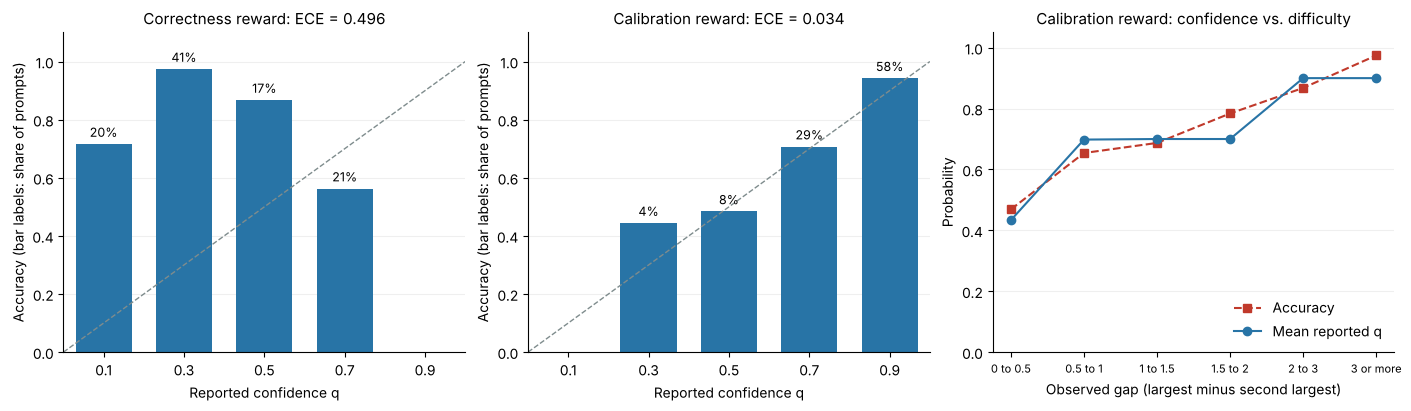

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.0), constrained_layout=True)
for ax, name in zip(axes[:2], ["Correctness reward", "Calibration reward"]):
    confidences, correct = reports[name]["confidences"], reports[name]["correct"]
    used = [level for level in LEVELS if (confidences == level).any()]
    shares = [(confidences == level).float().mean().item() for level in used]
    accuracies = [correct[confidences == level].mean().item() for level in used]
    ax.plot([0, 1], [0, 1], linestyle="--", color=COLORS[2], linewidth=1)
    bars = ax.bar([level.item() for level in used], accuracies, width=0.14, color=COLORS[0])
    ax.bar_label(bars, labels=[f"{s:.0%}" for s in shares], padding=3, fontsize=9)
    ax.set(xlim=(0, 1), ylim=(0, 1.1), xticks=LEVELS.tolist(), xlabel="Reported confidence q",
           ylabel="Accuracy (bar labels: share of prompts)")
    ax.set_title(f"{name}: ECE = {reports[name]['ece']:.3f}", fontsize=11)

test_gap_bins = gap_bin(observed_gap(test_obs))
gap_rows = list(range(1, len(GAP_LABELS)))
mean_q = [reports["Calibration reward"]["confidences"][test_gap_bins == b].mean().item() for b in gap_rows]
accuracy = [reports["Calibration reward"]["correct"][test_gap_bins == b].mean().item() for b in gap_rows]
x_labels = [GAP_LABELS[b] for b in gap_rows]
axes[2].plot(x_labels, accuracy, color=COLORS[1], linestyle="--", marker="s", label="Accuracy")
axes[2].plot(x_labels, mean_q, color=COLORS[0], marker="o", label="Mean reported q")
axes[2].set(ylim=(0, 1.05), xlabel="Observed gap (largest minus second largest)", ylabel="Probability")
axes[2].set_title("Calibration reward: confidence vs. difficulty", fontsize=11)
axes[2].tick_params(axis="x", labelsize=8)
axes[2].legend(frameon=False, loc="lower right")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

In the left panel, the correctness-reward policy's bars bear no relation to the diagonal. In the middle panel, the calibration-reward policy's bars come close to it. In the right panel, as the observed gap grows, accuracy rises from under one-half to nearly 1, and the reported confidence rises with it: **the policy learned to signal when a prompt is hard.** With only five levels, confidence can follow accuracy only in steps. The largest differences are for gaps from 1.5 to 2, where the policy reports 0.7 but is right a little more often (0.7 is still the closest level), and for the easiest prompts, where accuracy is above 95% but 0.9 is the highest level allowed. This matches Week 6's result.

**Two design choices from Week 5.** We retrain the calibration-reward policy three more times, changing one setting at a time and keeping the seed fixed:

1. **The KL weight.** $\beta=0$ (no penalty) and $\beta=1$, compared with $\beta=0.3$ above.
2. **Dividing by the group standard deviation.** Week 5's GRPO advantage $A_i=(r_i-\bar r)/(s+\epsilon)$, with $\epsilon=10^{-6}$ (as in Week 5), in place of $A_i=r_i-\bar r$. This is the `DIVIDE_BY_STD = True` experiment from Week 6's Section 5.

The second table shows, for each gap range of the chosen answer (the rows of the confidence table), how many test prompts fall in it, how often their greedy answers are correct, and which level each policy reports there.

**Predict before running:** as $\beta$ grows, what happens to the KL to the reference and to the sampled accuracy? Recall Week 6's note on dividing by $s$: where might the two advantage choices disagree?

In [10]:
beta_reports = {0.0: None, BETA: reports["Calibration reward"], 1.0: None}
for beta in (0.0, 1.0):
    beta_reports[beta] = full_report(train_with_rewards(calibration_reward, beta, show_progress=False),
                                     test_obs, test_true)

print(f"1. THE KL WEIGHT | calibration reward | test set, {len(test_obs)} observed prompts")
print(f"{'beta':<8}{'KL to ref.':>12}{'Sampled acc.':>14}{'Greedy acc.':>13}{'Log loss':>10}{'ECE':>8}")
print("-" * 65)
for beta, r in beta_reports.items():
    print(f"{beta:<8}{r['kl']:>12.4f}{r['sampled_accuracy']:>14.1%}{r['greedy_accuracy']:>13.1%}"
          f"{r['log_loss']:>10.4f}{r['ece']:>8.4f}")

std_policy = train_with_rewards(calibration_reward, BETA, divide_by_std=True, show_progress=False)
std_report = full_report(std_policy, test_obs, test_true)


@torch.no_grad()
def report_by_gap_range(model):
    answers, confidences = greedy_reports(model, test_obs)
    correct = (answers == test_answers).float()
    ranges = gap_bin(chosen_gap(test_obs, answers))
    rows = []
    for r in range(len(GAP_LABELS)):
        in_range = ranges == r
        levels = sorted(set(confidences[in_range].tolist()))
        rows.append((int(in_range.sum()), correct[in_range].mean().item() if in_range.any() else float("nan"),
                     "/".join(f"{level:.1f}" for level in levels) or "-"))
    return rows


print(f"\n2. DIVIDING BY THE GROUP STANDARD DEVIATION | beta = {BETA} | test set")
print(f"{'':<12}{'---------- A = r - mean ----------':>36}{'----- A = (r - mean) / (s + eps) -----':>40}")
print(f"{'Gap d':<12}{'Prompts':>10}{'Accuracy':>12}{'Reported q':>14}{'Prompts':>12}{'Accuracy':>12}{'Reported q':>14}")
print("-" * 88)
for label, (n1, a1, q1), (n2, a2, q2) in zip(GAP_LABELS, report_by_gap_range(calibration_policy),
                                             report_by_gap_range(std_policy)):
    acc1 = f"{a1:.1%}" if n1 else "-"
    acc2 = f"{a2:.1%}" if n2 else "-"
    print(f"{label:<12}{n1:>10}{acc1:>12}{q1:>14}{n2:>12}{acc2:>12}{q2:>14}")
print("-" * 88)
for name, r in [("A = r - mean", reports["Calibration reward"]), ("Divide by s", std_report)]:
    print(f"{name:<14} ECE = {r['ece']:.4f} | mean q = {r['mean_confidence']:.3f} | "
          f"greedy accuracy {r['greedy_accuracy']:.1%} | sampled accuracy {r['sampled_accuracy']:.1%}")

1. THE KL WEIGHT | calibration reward | test set, 2000 observed prompts
beta      KL to ref.  Sampled acc.  Greedy acc.  Log loss     ECE
-----------------------------------------------------------------
0.0           0.1762         79.8%        82.0%    0.5193  0.0314
0.3           0.1167         77.7%        81.7%    0.4549  0.0343
1.0           0.0225         72.1%        81.8%    0.4362  0.0512



2. DIVIDING BY THE GROUP STANDARD DEVIATION | beta = 0.3 | test set
              ---------- A = r - mean ----------  ----- A = (r - mean) / (s + eps) -----
Gap d          Prompts    Accuracy    Reported q     Prompts    Accuracy    Reported q
----------------------------------------------------------------------------------------
below 0             81       44.4%           0.3          47       48.9%           0.3
0 to 0.5           161       48.4%           0.5         194       47.9%           0.5
0.5 to 1           210       65.2%           0.7         211       64.9%           0.7
1 to 1.5           179       68.7%           0.7         179       68.7%           0.9
1.5 to 2           199       78.4%           0.7         199       78.4%           0.9
2 to 3             348       86.8%           0.9         348       86.8%           0.9
3 or more          822       97.4%           0.9         822       97.4%           0.9
---------------------------------------------------------

**The KL weight.** As $\beta$ grows from 0 to 1, the KL to the reference falls, and so does sampled accuracy. A smaller $\beta$ lets the policy concentrate more probability on its preferred answer. That raises sampled accuracy, but it also raises the log loss of the correct answer, because Week 1's log loss charges heavily for confident mistakes. Greedy accuracy barely changes, and the ECE stays small for all three values. As in Week 5, $\beta$ trades reward against closeness to the reference.

**Dividing by $s$.** The two versions report the same level in every gap range except 1 to 1.5 and 1.5 to 2. There, about 69% and 78% of greedy answers are correct, so the closest level is 0.7, which the main policy reports. The policy that divides by $s$ reports 0.9: its confidence drifted above its accuracy, as Week 6's note predicted. (In groups where all responses share one answer, dividing by $s$ makes the small reward differences of correct-answer groups count as much as the larger differences of wrong-answer groups, which favors higher $q$.)

Yet the policy that divides by $s$ has the **smaller** ECE. Its 0.9 bin combines these overconfident ranges with large-gap prompts that are right more than 95% of the time, where 0.9 is underconfident, and the two errors partly cancel. **A small ECE means each reported level is accurate on average over the answers that use it, not that every kind of prompt is calibrated.** Week 6 made the same point with a reporter that always states the overall accuracy; checking confidence against difficulty, as in the right panel above, reveals what ECE averages away.

## 4 · Answering with a guarantee

The trained policy is accurate on most prompts and states a useful confidence, but it is still sometimes wrong. As in Week 8, we can add a guarantee **without retraining**, using the separate calibration set. We use the main calibration-reward policy from Section 3 ($\beta=0.3$, $A_i=r_i-\bar r$).

We keep the calibration set separate from training and from the test set: the guarantee needs calibration scores that are exchangeable with a new prompt's score, and checking coverage on the same prompts that set $\hat q$ would give an optimistic answer.

**Conformal prediction sets.** Instead of one answer, return a set of answers $C(\tilde x)$ that contains the correct answer with probability at least $1-\alpha$. Split conformal prediction (Week 8) works as follows:

1. **Score the calibration set.** For each calibration prompt $i=1,\ldots,n$, compute $s_i=1-\pi_\theta(a_i^*\mid\tilde x_i)$, where $a_i^*$ is its correct answer. A large score means the policy gave the correct answer a low probability. (This score $s_i$ is unrelated to the group standard deviation $s$ in Section 3. Likewise, the error target $\varepsilon$ used below for selective answering is unrelated to the noise $\varepsilon_j$ in Section 1 and to Week 5's small constant $\epsilon$. We keep each week's notation.)
2. **Find the threshold.** Let $\hat q$ be the $\lceil (n+1)(1-\alpha)\rceil$-th smallest score. As in Week 8, $\hat q$ is a quantile of the scores, not a reported confidence $q$.
3. **Build the set.** For a new prompt, $C(\tilde x)=\{a: 1-\pi_\theta(a\mid\tilde x)\le\hat q\}$: keep every answer whose probability is at least $1-\hat q$.

**The guarantee.** If the calibration and test prompts are exchangeable (for example, independent draws from the same distribution, as here), then $P\big(a^*\in C(\tilde x)\big)\ge1-\alpha$, where the probability is over both the calibration set and the new prompt. This is coverage **on average over prompts**, not for each individual prompt. It holds for any fixed policy, whether or not its probabilities are calibrated; more informative probabilities tend to give smaller sets.

The code uses $\alpha=0.1$ (90% coverage) and $n=1000$, then checks coverage and set size on the 2000 test prompts, grouped by the observed gap.

In [11]:
ALPHA = 0.10
final_policy = calibration_policy

with torch.no_grad():
    cal_probs = final_policy.answer_distribution(cal_obs).probs
    test_probs = final_policy.answer_distribution(test_obs).probs



def conformal_threshold(scores, alpha):
    # As in Week 8: the ceil((n + 1)(1 - alpha))-th smallest score, or 1.0 if that rank exceeds n.
    n = len(scores)
    rank = math.ceil((n + 1) * (1 - alpha) - 1e-9)  # the tiny subtraction guards against rounding
    if rank > n:
        return 1.0, rank
    return scores.sort().values[rank - 1].item(), rank


cal_scores = 1 - cal_probs.gather(1, cal_answers[:, None]).squeeze(1)
n_cal = len(cal_scores)
q_hat, k = conformal_threshold(cal_scores, ALPHA)

prediction_sets = (1 - test_probs) <= q_hat
covered = prediction_sets.gather(1, test_answers[:, None]).squeeze(1).float()
set_sizes = prediction_sets.sum(dim=1)

print(f"Calibration set: n = {n_cal}, alpha = {ALPHA}")
print(f"k = ceil((n + 1)(1 - alpha)) = {k}   ->   q_hat = {k}-th smallest score = {q_hat:.4f}")
print(f"Keep every answer with probability >= 1 - q_hat = {1 - q_hat:.4f}")
print("=" * 64)
print(f"TEST SET | {len(test_obs)} observed prompts")
print(f"Coverage (correct answer in the set): {covered.mean().item():.1%}   (target: at least {1 - ALPHA:.0%})")
print(f"Average set size: {set_sizes.float().mean().item():.3f}")
print("Set sizes: " + "   ".join(f"{size} answer(s): {(set_sizes == size).float().mean().item():.1%}"
                                    for size in (1, 2, 3)))
print("-" * 64)
print(f"{'Observed gap':<16}{'Prompts':>9}{'Mean set size':>16}{'Coverage':>11}")
for b in gap_rows:
    in_range = test_gap_bins == b
    print(f"{GAP_LABELS[b]:<16}{int(in_range.sum()):>9}{set_sizes[in_range].float().mean().item():>16.3f}"
          f"{covered[in_range].mean().item():>11.1%}")

Calibration set: n = 1000, alpha = 0.1
k = ceil((n + 1)(1 - alpha)) = 901   ->   q_hat = 901-th smallest score = 0.7651
Keep every answer with probability >= 1 - q_hat = 0.2349
TEST SET | 2000 observed prompts
Coverage (correct answer in the set): 89.1%   (target: at least 90%)
Average set size: 1.207
Set sizes: 1 answer(s): 80.2%   2 answer(s): 19.0%   3 answer(s): 0.9%
----------------------------------------------------------------
Observed gap      Prompts   Mean set size   Coverage
0 to 0.5              241           2.012      90.5%
0.5 to 1              211           1.630      82.9%
1 to 1.5              179           1.201      72.1%
1.5 to 2              199           1.000      78.4%
2 to 3                348           1.000      86.8%
3 or more             822           1.000      97.4%


About 80% of test prompts receive a single answer, about 19% receive two, and a few receive all three. Overall coverage is close to the 90% target; in this run, it is slightly below, which we examine next.

**Set size follows difficulty.** When the observed gap is below 0.5, the average set contains about two answers. For gaps of 1.5 or more, every set contains one answer.

**Coverage is not 90% within each difficulty range.** It is lowest, roughly 70–80%, for gaps from 1 to 2. There, the policy's probabilities are concentrated enough to return a single answer, but that answer is often wrong. Coverage is above 95% for the easiest prompts. This matches the guarantee, which promises 90% coverage **on average over prompts**, not for each prompt or each type of prompt.

**What does "on average" mean here?** The calibration and test prompts are independent draws from the same distribution, so we can pool all 3000 of them, split them again at random into 1000 calibration and 2000 test prompts, and repeat Steps 2–3. The policy stays fixed; only the split changes. The code repeats this 5000 times and summarizes the test coverage.

In [12]:
all_scores = torch.cat([cal_scores, 1 - test_probs.gather(1, test_answers[:, None]).squeeze(1)])
split_generator = torch.Generator().manual_seed(SEED)
coverages = []
for _ in range(5000):
    order = torch.randperm(len(all_scores), generator=split_generator)
    calibration_scores, new_test_scores = all_scores[order[:n_cal]], all_scores[order[n_cal:]]
    threshold, _ = conformal_threshold(calibration_scores, ALPHA)
    coverages.append((new_test_scores <= threshold).float().mean().item())
coverages = torch.tensor(coverages)

print(f"{len(coverages)} random splits | {n_cal} calibration and {len(all_scores) - n_cal} test prompts each | alpha = {ALPHA}")
print(f"Mean test coverage:            {coverages.mean().item():.1%}   (theory: at least k/(n + 1) = {k}/{n_cal + 1} = {k / (n_cal + 1):.2%})")
print(f"Smallest and largest coverage: {coverages.min().item():.1%} and {coverages.max().item():.1%}")
print(f"Splits with coverage < 90%:    {(coverages < 1 - ALPHA - 1e-9).float().mean().item():.0%}")

5000 random splits | 1000 calibration and 2000 test prompts each | alpha = 0.1
Mean test coverage:            90.0%   (theory: at least k/(n + 1) = 901/1001 = 90.01%)
Smallest and largest coverage: 85.5% and 93.7%
Splits with coverage < 90%:    48%


Averaged over random splits, test coverage is about 90%, in line with the theory, while individual splits range from about 85% to about 94%. About half the splits fall below 90%. Our single test set's coverage, slightly below 90%, is therefore a typical outcome. The guarantee concerns the average over calibration and test data; any one calibration set can produce a threshold that is a little too low or too high. Larger calibration and test sets reduce this spread.

**Answer or abstain using the reported confidence.** A prediction set is one way to express uncertainty. Another is Week 8's **selective answering**: answer only when the confidence is at least a threshold $t$, and abstain otherwise. Week 8 thresholded the top probability of a fixed model; here we threshold the reported confidence $q$ directly, because the calibration reward trained it to track accuracy.

We want the **error rate among answered prompts** to be at most $\varepsilon=0.10$, and we want this claim to fail with probability at most $\delta=0.10$, the same targets as Week 8. For each threshold $t$, the calibration set gives $n_t$ answered prompts with $k_t$ errors. As in Week 8, we compute the one-sided **Clopper–Pearson upper bound** on the error rate: the largest error probability $e$ for which seeing $k_t$ or fewer errors among $n_t$ answers still has probability at least $\delta$. We accept $t$ only if this bound is at most $\varepsilon$.

As in Week 8, we scan thresholds in a fixed order, from strictest to most lenient ($t=0.9, 0.7, 0.5, 0.3, 0.1$), stop at the first threshold whose bound exceeds $\varepsilon$, and use the last threshold that passed. This **fixed-sequence testing** keeps the chance of choosing a threshold whose true error rate exceeds $\varepsilon$ at most $\delta$, over the draw of the calibration set.

The code prints the calibration-set scan, then checks the chosen threshold on the test set.

In [13]:
EPSILON_TARGET, DELTA = 0.10, 0.10
THRESHOLDS = (0.9, 0.7, 0.5, 0.3, 0.1)


def binomial_cdf(k, n, p):
    return sum(math.exp(math.lgamma(n + 1) - math.lgamma(i + 1) - math.lgamma(n - i + 1)
                        + i * math.log(p) + (n - i) * math.log1p(-p)) for i in range(k + 1))


def clopper_pearson_upper(k, n, delta, iterations=50):
    # Largest error probability e with P(Binomial(n, e) <= k) >= delta (as in Week 8).
    if n == 0 or k >= n:
        return 1.0
    low, high = k / n, 1.0
    for _ in range(iterations):
        middle = (low + high) / 2
        if binomial_cdf(k, n, middle) > delta:
            low = middle
        else:
            high = middle
    return high  # rounding up keeps the bound conservative


def selective_table(model, observed, true_numbers):
    answers, confidences = greedy_reports(model, observed)
    correct = (answers == true_numbers.argmax(dim=1)).float()
    rows = []
    for t in THRESHOLDS:
        answered = confidences >= t - 1e-6
        n_answered = int(answered.sum())
        errors = int((1 - correct[answered]).sum()) if n_answered else 0
        rows.append({"t": t, "fraction": answered.float().mean().item(), "n": n_answered, "errors": errors,
                     "error_rate": errors / n_answered if n_answered else float("nan")})
    return rows


cal_rows = selective_table(final_policy, cal_obs, cal_true)
chosen_t = None
print(f"SCAN ON THE CALIBRATION SET | {len(cal_obs)} prompts | epsilon = {EPSILON_TARGET}, delta = {DELTA}")
print(f"{'Threshold t':<13}{'Answered':>10}{'n_t':>7}{'k_t':>7}{'Error rate':>12}{'Upper bound':>13}{'Pass?':>11}")
print("-" * 73)
still_scanning = True
for row in cal_rows:
    if not still_scanning:
        break
    bound = clopper_pearson_upper(row["errors"], row["n"], DELTA) if row["n"] else 1.0
    passed = bound <= EPSILON_TARGET
    if passed:
        chosen_t = row["t"]
    else:
        still_scanning = False
    print(f"{row['t']:<13}{row['fraction']:>10.1%}{row['n']:>7}{row['errors']:>7}{row['error_rate']:>12.1%}"
          f"{bound:>13.1%}{('yes' if passed else 'no, stop'):>11}")
print("-" * 73)
print(f"Chosen threshold: answer only when q >= {chosen_t}" if chosen_t else "No threshold passed: abstain on every prompt.")

if chosen_t is not None:
    test_row = next(row for row in selective_table(final_policy, test_obs, test_true) if row["t"] == chosen_t)
    print("=" * 73)
    print(f"TEST SET | {len(test_obs)} observed prompts | threshold t = {chosen_t}")
    print(f"Answered: {test_row['fraction']:.1%} of prompts | error rate among answered: {test_row['error_rate']:.1%}"
          f"   (target: at most {EPSILON_TARGET:.0%})")
    print(f"For comparison, answering every prompt gives error rate "
          f"{1 - reports['Calibration reward']['greedy_accuracy']:.1%}")

SCAN ON THE CALIBRATION SET | 1000 prompts | epsilon = 0.1, delta = 0.1
Threshold t    Answered    n_t    k_t  Error rate  Upper bound      Pass?
-------------------------------------------------------------------------
0.9               59.2%    592     33        5.6%         7.0%        yes
0.7               89.6%    896    121       13.5%        15.1%   no, stop
-------------------------------------------------------------------------
Chosen threshold: answer only when q >= 0.9
TEST SET | 2000 observed prompts | threshold t = 0.9
Answered: 58.5% of prompts | error rate among answered: 5.7%   (target: at most 10%)
For comparison, answering every prompt gives error rate 18.3%


Only $t=0.9$ passes. About 6% of the calibration answers reported at 0.9 are wrong, and the upper bound, about 7%, is below $\varepsilon=0.10$. Adding the answers reported at 0.7 raises the error rate to about 14%, and its bound exceeds 10%, so the scan stops there.

On the test set, the policy answers a little under 60% of the prompts, and the error rate among those answers is about 6%, well below the target and far below the error rate of about 18% from answering every prompt. Thresholding $q$ works because the calibration reward made it track accuracy. Conformal sets and selective answering express the same uncertainty in two ways: **return more answers** or **answer fewer prompts**.

## 5 · A one-page map

**Follow one prompt through the whole pipeline.** Set `YOUR_OBSERVED` to three observed values, and `YOUR_TRUE` to three different integers from 1 through 9 (the hidden true numbers the verifier uses). The cell prints, for each stage, the answer probabilities and the log loss of the correct answer; then the trained policy's response, its reward, its conformal prediction set, and whether it would answer or abstain. Nothing here updates the weights.

**Try it:** start with two nearly equal observed values, as in `(5.0, 5.4, 1.0)`, then pull them apart, for example `(3.0, 7.0, 1.0)` with `YOUR_TRUE = (3, 7, 1)`. Before running, predict how the reported confidence, the prediction set, and the answer-or-abstain decision will change.

In [14]:
YOUR_OBSERVED = (5.0, 5.4, 1.0)
YOUR_TRUE = (5, 6, 1)

if (len(YOUR_TRUE) != 3 or len(set(YOUR_TRUE)) != 3
        or any(type(value) is not int or not 1 <= value <= 9 for value in YOUR_TRUE)):
    raise ValueError("YOUR_TRUE must contain three different integers from 1 through 9.")
if len(YOUR_OBSERVED) != 3:
    raise ValueError("YOUR_OBSERVED must contain three numbers.")

observed = torch.tensor(YOUR_OBSERVED, dtype=torch.float32)[None, :]
correct_index = max(range(3), key=lambda j: YOUR_TRUE[j])

print("=" * 70)
print(format_prompt(observed[0]))
print(f"Hidden true numbers: {YOUR_TRUE}  ->  correct answer {LETTERS[correct_index]}")
print("-" * 70)
print(f"{'Stage':<34}" + "".join(f"{f'P({l})':>9}" for l in LETTERS) + f"{'Log loss':>10}")
with torch.no_grad():
    for stage, model in [("Start (Week 1)", initial_policy), ("Reference after SFT (Week 2)", reference_policy),
                         ("After rewards (Weeks 4-6)", final_policy)]:
        probabilities = model.answer_distribution(observed).probs[0]
        print(f"{stage:<34}" + "".join(f"{p.item():>9.4f}" for p in probabilities)
              + f"{-math.log(probabilities[correct_index].item()):>10.4f}")
    answer, confidence = greedy_reports(final_policy, observed)
    probabilities = final_policy.answer_distribution(observed).probs[0]
    d = chosen_gap(observed, answer)

answer, confidence = answer.item(), confidence.item()
c = verify(YOUR_TRUE, answer)
prediction_set = [LETTERS[j] for j in range(3) if 1 - probabilities[j].item() <= q_hat]
print("-" * 70)
print(f"Greedy response: {LETTERS[answer]} {confidence:.1f}   (gap d = {d.item():+.2f}, row '{GAP_LABELS[gap_bin(d).item()]}')")
print(f"Correct (c) = {c:.0f}, reward c - (q - c)^2 = {c - (confidence - c) ** 2:.2f}   (Week 6)")
print(f"90% conformal prediction set: {{{', '.join(prediction_set)}}}   (Week 8)")
if chosen_t is not None:
    decision = "answer" if confidence >= chosen_t - 1e-6 else "abstain"
    print(f"Selective answering with t = {chosen_t}: {decision}   (Week 8)")
print("=" * 70)

Which number is largest?
A: 5.0    B: 5.4    C: 1.0
Respond with A, B, or C, then your confidence that the answer is correct.
Hidden true numbers: (5, 6, 1)  ->  correct answer B
----------------------------------------------------------------------
Stage                                  P(A)     P(B)     P(C)  Log loss
Start (Week 1)                       0.3333   0.3333   0.3333    1.0986
Reference after SFT (Week 2)         0.4386   0.5071   0.0543    0.6790
After rewards (Weeks 4-6)            0.4423   0.5554   0.0023    0.5880
----------------------------------------------------------------------
Greedy response: B 0.5   (gap d = +0.40, row '0 to 0.5')
Correct (c) = 1, reward c - (q - c)^2 = 0.75   (Week 6)
90% conformal prediction set: {A, B}   (Week 8)
Selective answering with t = 0.9: abstain   (Week 8)


For the default prompt, the two largest observed values are close (5.0 and 5.4). Each stage makes the answer `B` more likely, but the trained policy reports only 0.5 (the gap $d=0.4$ falls in the `0 to 0.5` row), the conformal set keeps both `A` and `B`, and selective answering abstains. The stated confidence, the prediction set, and the abstain decision all express the same uncertainty.

### Where each week's idea appeared today

| Week | Idea | Where it appeared today |
|---|---|---|
| 1 | Next-token probabilities, log loss $-\ln p$, perplexity | Section 1: the uniform start has log loss $\ln 3$ and perplexity 3; we tracked log loss at every stage. |
| 2 | Supervised fine-tuning on desired responses | Section 2: 100 updates toward the largest true number produced the reference policy. |
| 3 | Greedy decoding, sampling, temperature | Sections 1–2: temperature cannot change a uniform policy; after training, it changes sampled accuracy but never greedy accuracy. |
| 4 | Verifier, reward, policy gradient: sample → verify → update | Section 3: the verifier checks each sampled answer against the true numbers. |
| 5 | Multi-part log-probability, group-relative advantages, KL penalty | Section 3: two-part responses, groups of $G=8$, the choice of $\beta$, and whether to divide by $s$. |
| 6 | Calibration reward $c-(q-c)^2$, confidence table, reliability diagrams, ECE | Section 3: stated confidence that tracks accuracy, and what ECE averages over. |
| 7 | Preferences, Bradley–Terry model, DPO | Not needed today, because our task has a verifier. Without one (for example, for helpfulness), preference data would supply the learning signal. |
| 8 | Conformal prediction sets, selective answering | Section 4: 90% prediction sets and answer-or-abstain with an error bound, using a fixed policy. |
| 9 | Embeddings and retrieval | Not used today. Loosely, retrieving good evidence before answering plays the role of seeing the numbers with less noise: more prompts become easy. |

## Recap

We followed one task through the whole sequence of discussions:

**Tokens → probabilities → loss → updates → sampled responses → rewards → calibrated confidence → guarantees**

The policy's response had two parts, and its probabilities gave a log loss we could track (Weeks 1 and 3). Supervised updates produced a reasonable reference policy (Week 2). Sampling groups of responses, verifying them, and weighting log-probabilities by group-relative advantages improved the policy, while a KL penalty kept it close to the reference (Weeks 4 and 5). A proper scoring rule in the reward made the stated confidence track accuracy (Week 6). Finally, a separate calibration set turned the fixed policy into prediction sets and selective answers with stated guarantees (Week 8).

### Check your understanding

1. At the start, all logits were zero. Why was the perplexity exactly 3, and why did temperature have no effect?
2. Supervised training and the reward stage both used the correct answers. What did the reward stage learn that supervised training on answers could not teach?
3. In a group where all $G$ responses receive the same reward, what are the advantages, and what does the group contribute to the update? Why does this happen less often with the calibration reward than with $R=c$?
4. Why does the reward $c-(q-c)^2$ encourage honest confidence, while a reward of $q$ for a correct answer and 0 for a wrong one would not?
5. In our saved run, the test-set coverage was slightly below 90%. Does that contradict the conformal guarantee? Does the guarantee say that each prompt's set contains the correct answer with probability 0.9?

<details><summary>Answers · open after discussing</summary>

1. Each answer had probability $1/3$, so the log loss was $-\ln(1/3)=\ln 3$ on every prompt and the perplexity was $e^{\ln 3}=3$. Temperature divides the logits by $T$, and $0/T=0$, so the distribution stays uniform.
2. How to report confidence. There were no desired confidence levels to imitate. The reward scores whichever level is sampled, so the policy learns which level earns the most reward for each gap range. The reward stage also learns from the policy's own samples rather than from fixed targets.
3. Every advantage $r_i-\bar r$ is zero, so the group adds nothing to the policy-gradient term; only the KL penalty still acts. With $R=c$, this happens whenever all $G$ answers are correct or all are wrong. With the calibration reward, rewards still differ whenever the sampled confidence levels differ.
4. If the answer is correct with probability $p$, the expected Brier penalty is $\mathbb{E}[(q-c)^2]=(q-p)^2+p(1-p)$, which is smallest at $q=p$, so the best level is the one closest to $p$. With a reward of $q$ only for correct answers, the expected reward is $pq$, which increases with $q$, so the best report is always the highest level, whatever $p$ is.
5. No. The guarantee is an average over calibration and test data, so one test set can fall slightly below 90%; across random splits, coverage averaged about 90%. It is also not a guarantee for each prompt: coverage was below 80% for some gap ranges and above 95% for the easiest prompts.

</details>

## References and further reading

- [OpenAI Spinning Up: Introduction to policy optimization](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html): policy gradients and baselines.
- [Damani et al. (2025): Beyond binary rewards](https://arxiv.org/abs/2507.16806): calibration rewards.
- [Angelopoulos and Bates (2021): A gentle introduction to conformal prediction](https://arxiv.org/abs/2107.07511): coverage guarantees.